## Classification in Python with PyTorch

In this section, we implement a classification model using PyTorch, a deep learning framework for building and training neural networks. We use a Multi-Layer Perceptron (MLP) to classify data points into different classes based on their input features.

The implementation covers neural network construction, forward propagation, loss computation, backpropagation, and parameter optimization. We also investigate how network depth affects classification accuracy, model complexity, and training time.

## Classification in Python with PyTorch

In this section, we implement a Multi-Layer Perceptron (MLP) using PyTorch to classify non-linearly separable data. We study how neural networks learn decision boundaries and how different architectural and training parameters affect classification performance.

### Objectives

- Understand the classification problem and MLP architecture.
- Implement forward propagation, loss computation, and gradient descent.
- Visualize how the decision boundary evolves during training.
- Investigate the effects of network depth, width, activation functions, learning rate, data noise, and training set size on classification accuracy.
- Compare model complexity, computational cost, and predictive performance.

**Class 0:**

$$
\mathbf{x}_0 =
\begin{pmatrix}
\cos t \\
\sin t
\end{pmatrix}
+ \boldsymbol{\varepsilon}
$$

**Class 1:**

$$
\mathbf{x}_1 =
\begin{pmatrix}
1-\cos t \\
2-\sin t
\end{pmatrix}
+ \boldsymbol{\varepsilon}
$$

where

$$
\boldsymbol{\varepsilon} \sim \mathcal{N}(\mathbf{0}, \sigma^2 I).
$$

For each class, the parameter `t` is equally spaced in the interval `[0, π]`. Class 0 contains `floor(n/2)` points, while class 1 contains the remaining points. The generated points are then shuffled.

Class 0 represents the upper moon, and class 1 represents the lower moon. The tips of each moon extend into the opening of the other moon.

The parameter `σ` controls the noise level. For large values of `σ`, the two classes increasingly overlap, making classification more difficult.

In [5]:
%pip install scikit-learn

  Using cached scikit_learn-1.9.1-cp314-cp314-macosx_12_0_arm64.whl.metadata (9.3 kB)
  Using cached scipy-1.18.1-cp314-cp314-macosx_14_0_arm64.whl.metadata (62 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached threadpoolctl-3.8.0-py3-none-any.whl.metadata (29 kB)
Using cached scikit_learn-1.9.1-cp314-cp314-macosx_12_0_arm64.whl (8.3 MB)
Using cached joblib-1.6.0-py3-none-any.whl (306 kB)
Using cached scipy-1.18.1-cp314-cp314-macosx_14_0_arm64.whl (20.5 MB)
Using cached threadpoolctl-3.8.0-py3-none-any.whl (32 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6/6 [scikit-learn] [scikit-learn]

[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [23]:

import torch
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
import torch
import torch.nn as nn


In [19]:



def make_data(
    n_samples=800,
    noise=0.18,
    seed=3,
    test_size=0.25,
    split_seed=1
):
    # 1. Generate the two-moons dataset
    X, y = make_moons(
        n_samples=n_samples,
        noise=noise,
        random_state=seed
    )

    # 2. Split into training and testing sets
    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=test_size,
        random_state=split_seed
    )

    # 3. Standardize the features
    scaler = StandardScaler()

    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)

    # 4. Convert NumPy arrays into PyTorch tensors
    X_train = torch.tensor(X_train, dtype=torch.float32)
    y_train = torch.tensor(y_train, dtype=torch.long)

    X_test = torch.tensor(X_test, dtype=torch.float32)
    y_test = torch.tensor(y_test, dtype=torch.long)

    return X_train, y_train, X_test, y_test

In [21]:
X_train, y_train, X_test, y_test = make_data()

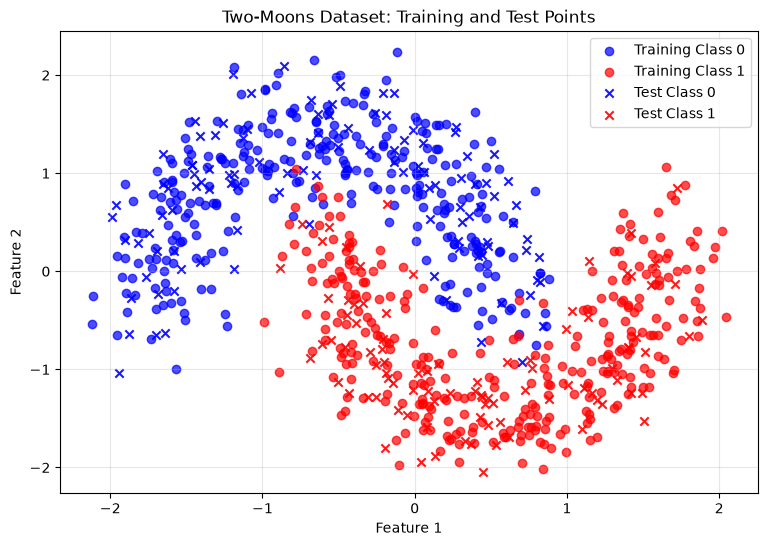

In [22]:
# Convert PyTorch tensors to NumPy arrays for plotting
X_train_np = X_train.numpy()
y_train_np = y_train.numpy()

X_test_np = X_test.numpy()
y_test_np = y_test.numpy()

# Create the figure
plt.figure(figsize=(9, 6))

# Plot training points
for class_id, color in zip([0, 1], ["blue", "red"]):

    mask = y_train_np == class_id

    plt.scatter(
        X_train_np[mask, 0],
        X_train_np[mask, 1],
        color=color,
        marker="o",
        label=f"Training Class {class_id}",
        alpha=0.7
    )

# Plot test points
for class_id, color in zip([0, 1], ["blue", "red"]):

    mask = y_test_np == class_id

    plt.scatter(
        X_test_np[mask, 0],
        X_test_np[mask, 1],
        color=color,
        marker="x",
        label=f"Test Class {class_id}",
        alpha=0.9
    )

# Add labels and title
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Two-Moons Dataset: Training and Test Points")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [24]:



class MLP(nn.Module):
    """
    Fully connected network with depth hidden layers.

    Every hidden layer has width neurons.
    For depth = 0, the model is a single linear layer.
    The outputs are logits (no softmax).
    """

    def __init__(
        self,
        input_dim=2,
        output_dim=2,
        width=32,
        depth=2,
        activation=nn.ReLU
    ):
        super().__init__()

        # Store all layers in a list
        layers = []

        # Build hidden layers
        for i in range(depth):

            # First hidden layer receives input_dim features.
            # Remaining hidden layers receive width features.
            in_features = input_dim if i == 0 else width

            layers.append(nn.Linear(in_features, width))
            layers.append(activation())

        # Final output layer
        if depth > 0:
            layers.append(nn.Linear(width, output_dim))
        else:
            layers.append(nn.Linear(input_dim, output_dim))

        # Combine all layers into one sequential network
        self.network = nn.Sequential(*layers)

    def forward(self, x):

        return self.network(x)

In [25]:
model = MLP(
    input_dim=2,
    output_dim=2,
    width=32,
    depth=2,
    activation=nn.ReLU
)

print(model)

MLP(
  (network): Sequential(
    (0): Linear(in_features=2, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=2, bias=True)
  )
)
